In [ ]:
from pathlib import Path

ROOT = Path('/content/drive/MyDrive/Logika Ui')
AKAR = ROOT / 'KTI_KARHUTLA'
HASIL = AKAR / 'hasil'
LAIN = AKAR / 'lainnya'

GADM_SHP = ROOT / 'GADM 2' / 'gadm41_IDN_2.shp'
GAMBUT_GEOJSON = LAIN / 'Indonesia_Peat_Lands.geojson'

TABEL_UTAMA = HASIL / 'tabel_gabungan_nasional_semua_bulan.csv'
PROB_FINAL = HASIL / 'prob_final_nasional.npz'
GAMBUT_KAB = HASIL / 'gambut_kabkota.csv'
VALIDASI_SIPONGI = HASIL / 'validasi_sipongi_firms_kabtahun.csv'
PRIORITAS_HARIAN = HASIL / 'prioritas_harian.csv'

PRIORITAS = ['Riau', 'Jambi', 'Sumatera Selatan',
             'Kalimantan Barat', 'Kalimantan Tengah', 'Kalimantan Selatan']
CRS_LUAS = 'EPSG:6933'
TAU = 0.05

Mounted at /content/drive
(1187441, 46) | 479 wilayah | 2020-01-01 sampai 2026-10-14
       hari  era5  himawari  firms
tahun                             
2020    366   1.0     1.000  1.000
2021    365   1.0     1.000  0.997
2022    365   1.0     0.948  0.959
2023    365   1.0     0.375  0.995
2024    366   1.0     0.997  0.945
2025    365   1.0     0.997  0.997
2026    287   1.0     1.000  0.948


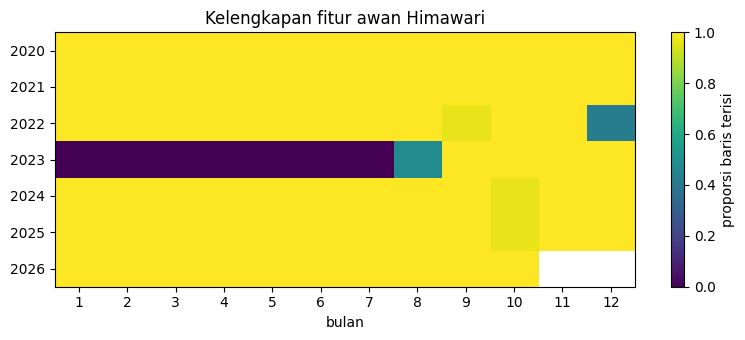

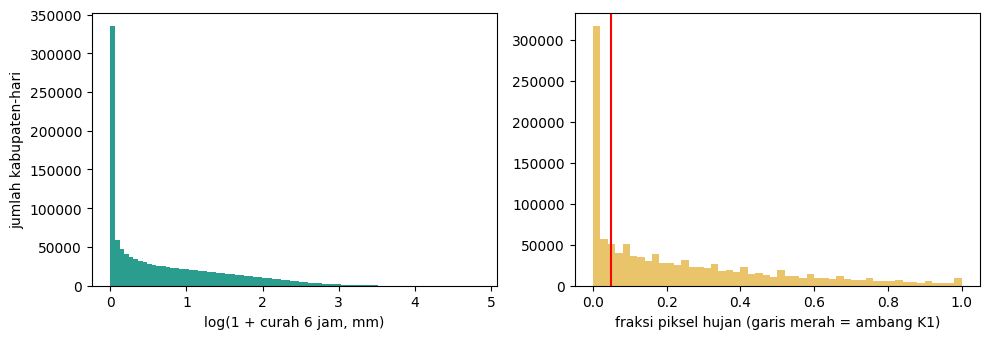

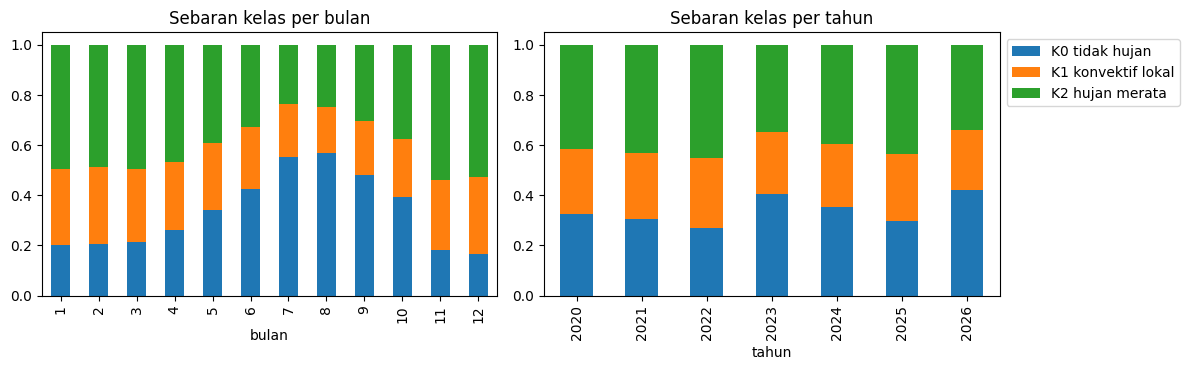

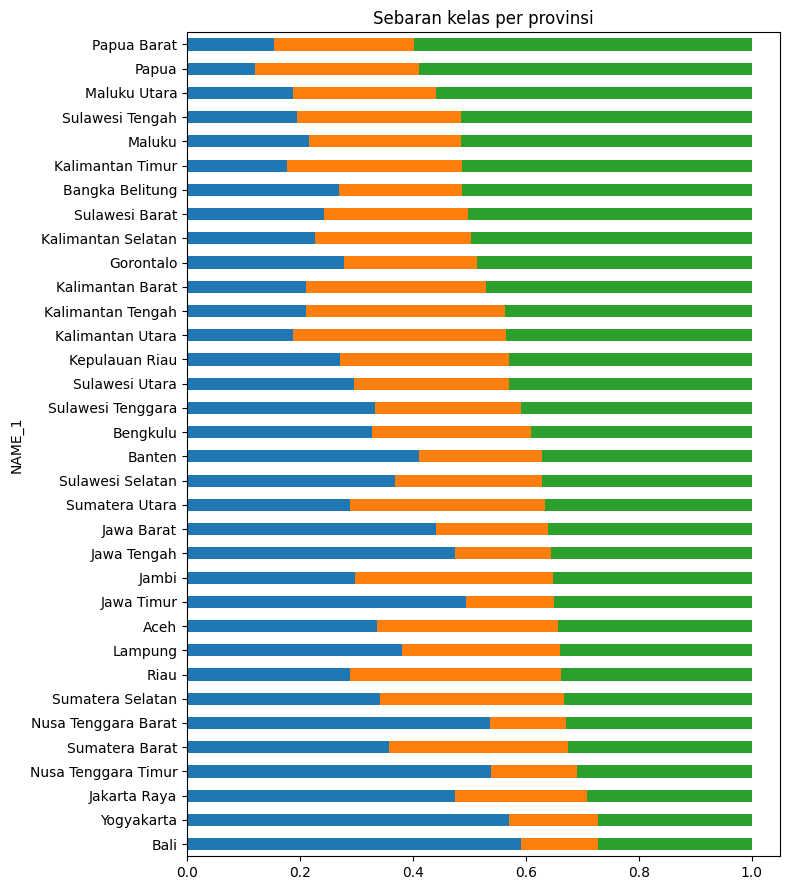

       cape_00  tcwv_00  r_700_00  tcc_00  him_lt233  him_f0
kelas                                                       
0      262.801   41.597    54.370   0.627      0.415   0.364
1      369.651   49.585    72.528   0.834      0.638   0.153
2      403.281   51.989    78.419   0.873      0.707   0.094


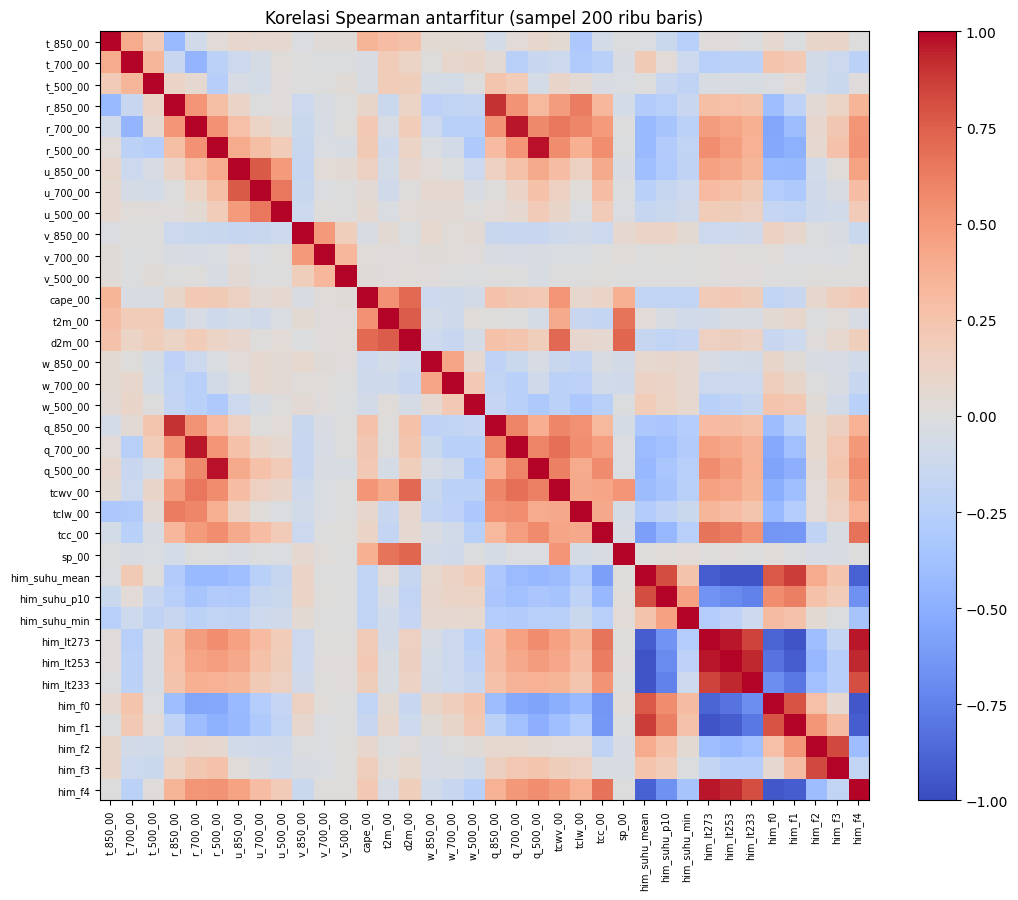

pasangan fitur dengan korelasi mutlak > 0,9: 13 dari 630
           dengan_K1  dengan_K2   maks
q_700_00       0.069      0.427  0.427
him_f0        -0.083     -0.424  0.424
r_700_00       0.071      0.416  0.416
him_f4         0.091      0.401  0.401
q_850_00       0.034      0.375  0.375
q_500_00       0.095      0.373  0.373
tcwv_00        0.088      0.372  0.372
him_lt273      0.101      0.357  0.357
him_lt253      0.092      0.344  0.344
r_500_00       0.102      0.341  0.341


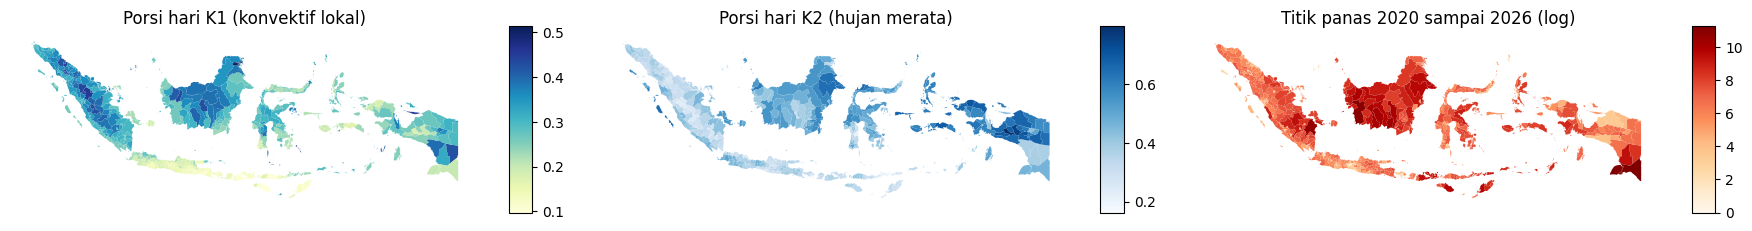

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
ROOT = Path('/content/drive/MyDrive/Logika Ui')
HASIL = ROOT / 'KTI_KARHUTLA' / 'hasil'

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

TAU = 0.05
NAMA_KELAS = {0: 'K0 tidak hujan', 1: 'K1 konvektif lokal', 2: 'K2 hujan merata'}
FILE = HASIL / 'tabel_gabungan_nasional_semua_bulan.csv'

kepala = pd.read_csv(FILE, nrows=0).columns
fitur_era = [c for c in kepala if c.endswith('_00')]
fitur_him = [c for c in kepala if c.startswith('him_') and c not in ('him_n', 'him_f5')]
kolom = ['tanggal', 'GID_2', 'NAME_1', 'hujan_rata', 'frac_hujan', 'him_n',
         'titik_panas', 'tahun', 'bulan'] + fitur_era + fitur_him

t = pd.read_csv(FILE, usecols=kolom, parse_dates=['tanggal'])
curah = t['hujan_rata'] * 6
t['kelas'] = np.where(curah >= 1, 2, np.where(t['frac_hujan'] >= TAU, 1, 0))
print(t.shape, '|', t['GID_2'].nunique(), 'wilayah |', t['tanggal'].min().date(), 'sampai', t['tanggal'].max().date())

cakupan = t.groupby('tahun').agg(
    hari=('tanggal', 'nunique'),
    era5=('t2m_00', lambda s: s.notna().mean()),
    himawari=('him_n', lambda s: s.notna().mean()),
    firms=('titik_panas', lambda s: s.notna().mean()),
).round(3)
print(cakupan)

ada_him = t.assign(ada=t['him_n'].notna().astype(float)).pivot_table(
    index='tahun', columns='bulan', values='ada', aggfunc='mean')
fig, ax = plt.subplots(figsize=(8, 3.5))
gambar = ax.imshow(ada_him.values, aspect='auto', cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(ada_him.shape[1]))
ax.set_xticklabels(ada_him.columns)
ax.set_yticks(range(ada_him.shape[0]))
ax.set_yticklabels(ada_him.index)
ax.set_xlabel('bulan')
ax.set_title('Kelengkapan fitur awan Himawari')
fig.colorbar(gambar, ax=ax, label='proporsi baris terisi')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(np.log1p(curah), bins=80, color='#2a9d8f')
ax[0].set_xlabel('log(1 + curah 6 jam, mm)')
ax[0].set_ylabel('jumlah kabupaten-hari')
ax[1].hist(t['frac_hujan'], bins=50, color='#e9c46a')
ax[1].axvline(TAU, color='red')
ax[1].set_xlabel('fraksi piksel hujan (garis merah = ambang K1)')
plt.tight_layout()
plt.show()


def porsi(kunci):
    return pd.crosstab(t[kunci], t['kelas'], normalize='index').rename(columns=NAMA_KELAS)


fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
porsi('bulan').plot.bar(stacked=True, ax=ax[0], legend=False)
ax[0].set_title('Sebaran kelas per bulan')
porsi('tahun').plot.bar(stacked=True, ax=ax[1])
ax[1].set_title('Sebaran kelas per tahun')
ax[1].legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

per_prov = porsi('NAME_1').sort_values('K2 hujan merata')
per_prov.plot.barh(stacked=True, figsize=(8, 9), legend=False)
plt.title('Sebaran kelas per provinsi')
plt.tight_layout()
plt.show()

s = t.sample(min(200_000, len(t)), random_state=1)
print(s.groupby('kelas')[['cape_00', 'tcwv_00', 'r_700_00', 'tcc_00', 'him_lt233', 'him_f0']].mean().round(3))

semua = fitur_era + fitur_him
kor = s[semua].corr(method='spearman')
fig, ax = plt.subplots(figsize=(11, 9))
gambar = ax.imshow(kor.values, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(semua)))
ax.set_xticklabels(semua, rotation=90, fontsize=7)
ax.set_yticks(range(len(semua)))
ax.set_yticklabels(semua, fontsize=7)
ax.set_title('Korelasi Spearman antarfitur (sampel 200 ribu baris)')
fig.colorbar(gambar, ax=ax)
plt.tight_layout()
plt.show()

pasangan = kor.where(np.triu(np.ones(kor.shape, bool), k=1)).stack()
print('pasangan fitur dengan korelasi mutlak > 0,9:', int((pasangan.abs() > 0.9).sum()), 'dari', len(pasangan))

k1 = s[semua].corrwith((s['kelas'] == 1).astype(float), method='spearman')
k2 = s[semua].corrwith((s['kelas'] == 2).astype(float), method='spearman')
print(pd.DataFrame({'dengan_K1': k1, 'dengan_K2': k2}).assign(maks=lambda d: d.abs().max(axis=1))
      .sort_values('maks', ascending=False).head(10).round(3))

gadm2 = gpd.read_file(ROOT / 'GADM 2' / 'gadm41_IDN_2.shp')
per_kab = pd.DataFrame({
    'porsi_K1': t.groupby('GID_2')['kelas'].apply(lambda x: (x == 1).mean()),
    'porsi_K2': t.groupby('GID_2')['kelas'].apply(lambda x: (x == 2).mean()),
    'log_titik_panas': np.log1p(t.groupby('GID_2')['titik_panas'].sum()),
}).reset_index()
peta = gadm2.merge(per_kab, on='GID_2', how='left')
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, kol, cmap, judul in [(ax[0], 'porsi_K1', 'YlGnBu', 'Porsi hari K1 (konvektif lokal)'),
                            (ax[1], 'porsi_K2', 'Blues', 'Porsi hari K2 (hujan merata)'),
                            (ax[2], 'log_titik_panas', 'OrRd', 'Titik panas 2020 sampai 2026 (log)')]:
    peta.plot(column=kol, cmap=cmap, legend=True, ax=a, linewidth=0.1,
              missing_kwds={'color': 'lightgrey'})
    a.set_title(judul)
    a.set_axis_off()
plt.tight_layout()
plt.show()